#  Business Case

This project is about recognizing whether a person is walking or running using sensor data from a wearable device (like a smartwatch or fitness band). The data comes from motion sensors like accelerometers and gyroscopes.

Why is this useful?
- **Fitness apps** can automatically track user activity.
- **Healthcare** providers can monitor patients' movement patterns.
- **Smart devices** can respond based on your movement (e.g., start music when running).
- **Insurance companies** can reward healthy behavior if activity is verified.

By training a machine learning model to detect these activities accurately, we can create smarter, more helpful applications in the real world.

#  Problem Statement

We want to build a model that can tell whether someone is walking or running, just by looking at motion sensor data collected from a wearable device.

The model will use:
- **Accelerometer data** (`acceleration_x`, `acceleration_y`, `acceleration_z`)
- **Gyroscope data** (`gyro_x`, `gyro_y`, `gyro_z`)
- Other info like `time`, `date`, `username`, and which `wrist` the device was on.

Our target column is `activity`:
- `0` means walking
- `1` means running

Our goal is to predict this correctly using machine learning.

In [1]:
import pandas as pd  # Importing pandas for data manipulation and analysis (e.g., reading CSVs, DataFrames).
import numpy as np  # Importing NumPy for numerical operations, array manipulations, and mathematical functions.
import seaborn as sns  # Importing Seaborn for advanced and visually appealing statistical data visualization.
import matplotlib.pyplot as plt  # Importing Matplotlib's pyplot for plotting basic graphs like line plots, histograms, etc.
import warnings  # Importing warnings module to manage warning messages in output.
warnings.filterwarnings('ignore')  # This line suppresses all warning messages to keep output clean during execution.

In [2]:
data = pd.read_csv('walkrun.csv')  # Reads the CSV file named 'walkrun.csv' and stores it in a DataFrame called 'data'
data  # Displays the entire DataFrame (not recommended for large datasets as it may flood the output)

,date,time,username,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,2017-6-30,13:51:15:847724020,viktor,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,2017-6-30,13:51:16:246945023,viktor,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,2017-6-30,13:51:16:446233987,viktor,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,2017-6-30,13:51:16:646117985,viktor,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,2017-6-30,13:51:16:846738994,viktor,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922
...,...,...,...,...,...,...,...,...,...,...,...
88583,2017-7-9,20:9:15:317911028,viktor,0,0,0.3084,-0.8376,-0.1327,0.4823,2.0124,0.6048
88584,2017-7-9,20:9:15:517889022,viktor,0,0,0.4977,-1.0027,-0.4397,0.1022,-1.2565,-0.0761
88585,2017-7-9,20:9:15:717828989,viktor,0,0,0.4587,-1.1780,-0.2827,-1.4500,-0.2792,-1.2616
88586,2017-7-9,20:9:15:917932987,viktor,0,0,0.2590,-0.8582,-0.0759,-1.5165,0.4560,-1.7755


In [3]:
drop_col = ['date', 'time', 'username']  # List of column names to be dropped from the DataFrame
data.drop(drop_col, axis=1, inplace=True)  # Drops the specified columns from 'data' along columns (axis=1) and updates the DataFrame in-place

## Basic Checks

In [4]:
data.head()

,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


In [5]:
data.info() # printing the basic information of data like , type of data in columns and null values in columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88588 entries, 0 to 88587
Data columns (total 8 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   wrist           88588 non-null  int64  
 1   activity        88588 non-null  int64  
 2   acceleration_x  88588 non-null  float64
 3   acceleration_y  88588 non-null  float64
 4   acceleration_z  88588 non-null  float64
 5   gyro_x          88588 non-null  float64
 6   gyro_y          88588 non-null  float64
 7   gyro_z          88588 non-null  float64
dtypes: float64(6), int64(2)
memory usage: 5.4 MB


In [6]:
data.describe()  # Generates descriptive statistics for numerical columns in the DataFrame

,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
count,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000,88588.000000
mean,0.522170,0.500801,-0.074811,-0.562585,-0.313956,0.004160,0.037203,0.022327
std,0.499511,0.500002,1.009299,0.658458,0.486815,1.253423,1.198725,1.914423
min,0.000000,0.000000,-5.350500,-3.299000,-3.753800,-4.430600,-7.464700,-9.480000
25%,0.000000,0.000000,-0.381800,-1.033500,-0.376000,-0.920700,-0.644825,-1.345125
50%,1.000000,1.000000,-0.059500,-0.759100,-0.221000,0.018700,0.039300,0.006900
75%,1.000000,1.000000,0.355500,-0.241775,-0.085900,0.888800,0.733700,1.398200
max,1.000000,1.000000,5.603300,2.668000,1.640300,4.874200,8.498000,11.266200


#  Dataset Summary

We’re using a dataset named `walkrun.csv` which has:
- **88,588 rows** (sensor readings)
- **11 columns**
- No missing values (clean data)

Here’s what the columns mean:
- `date`, `time`: When the data was recorded
- `username`: Whose data it is
- `wrist`: Left or right wrist (0 means left)
- `activity`: 0 = walk, 1 = run (this is what we’re predicting)
- `acceleration_x/y/z`: Movement in 3 directions
- `gyro_x/y/z`: Rotation in 3 directions

It’s a time-series dataset, and we’ll use it for classification.

# EDA

## Univarient analysis

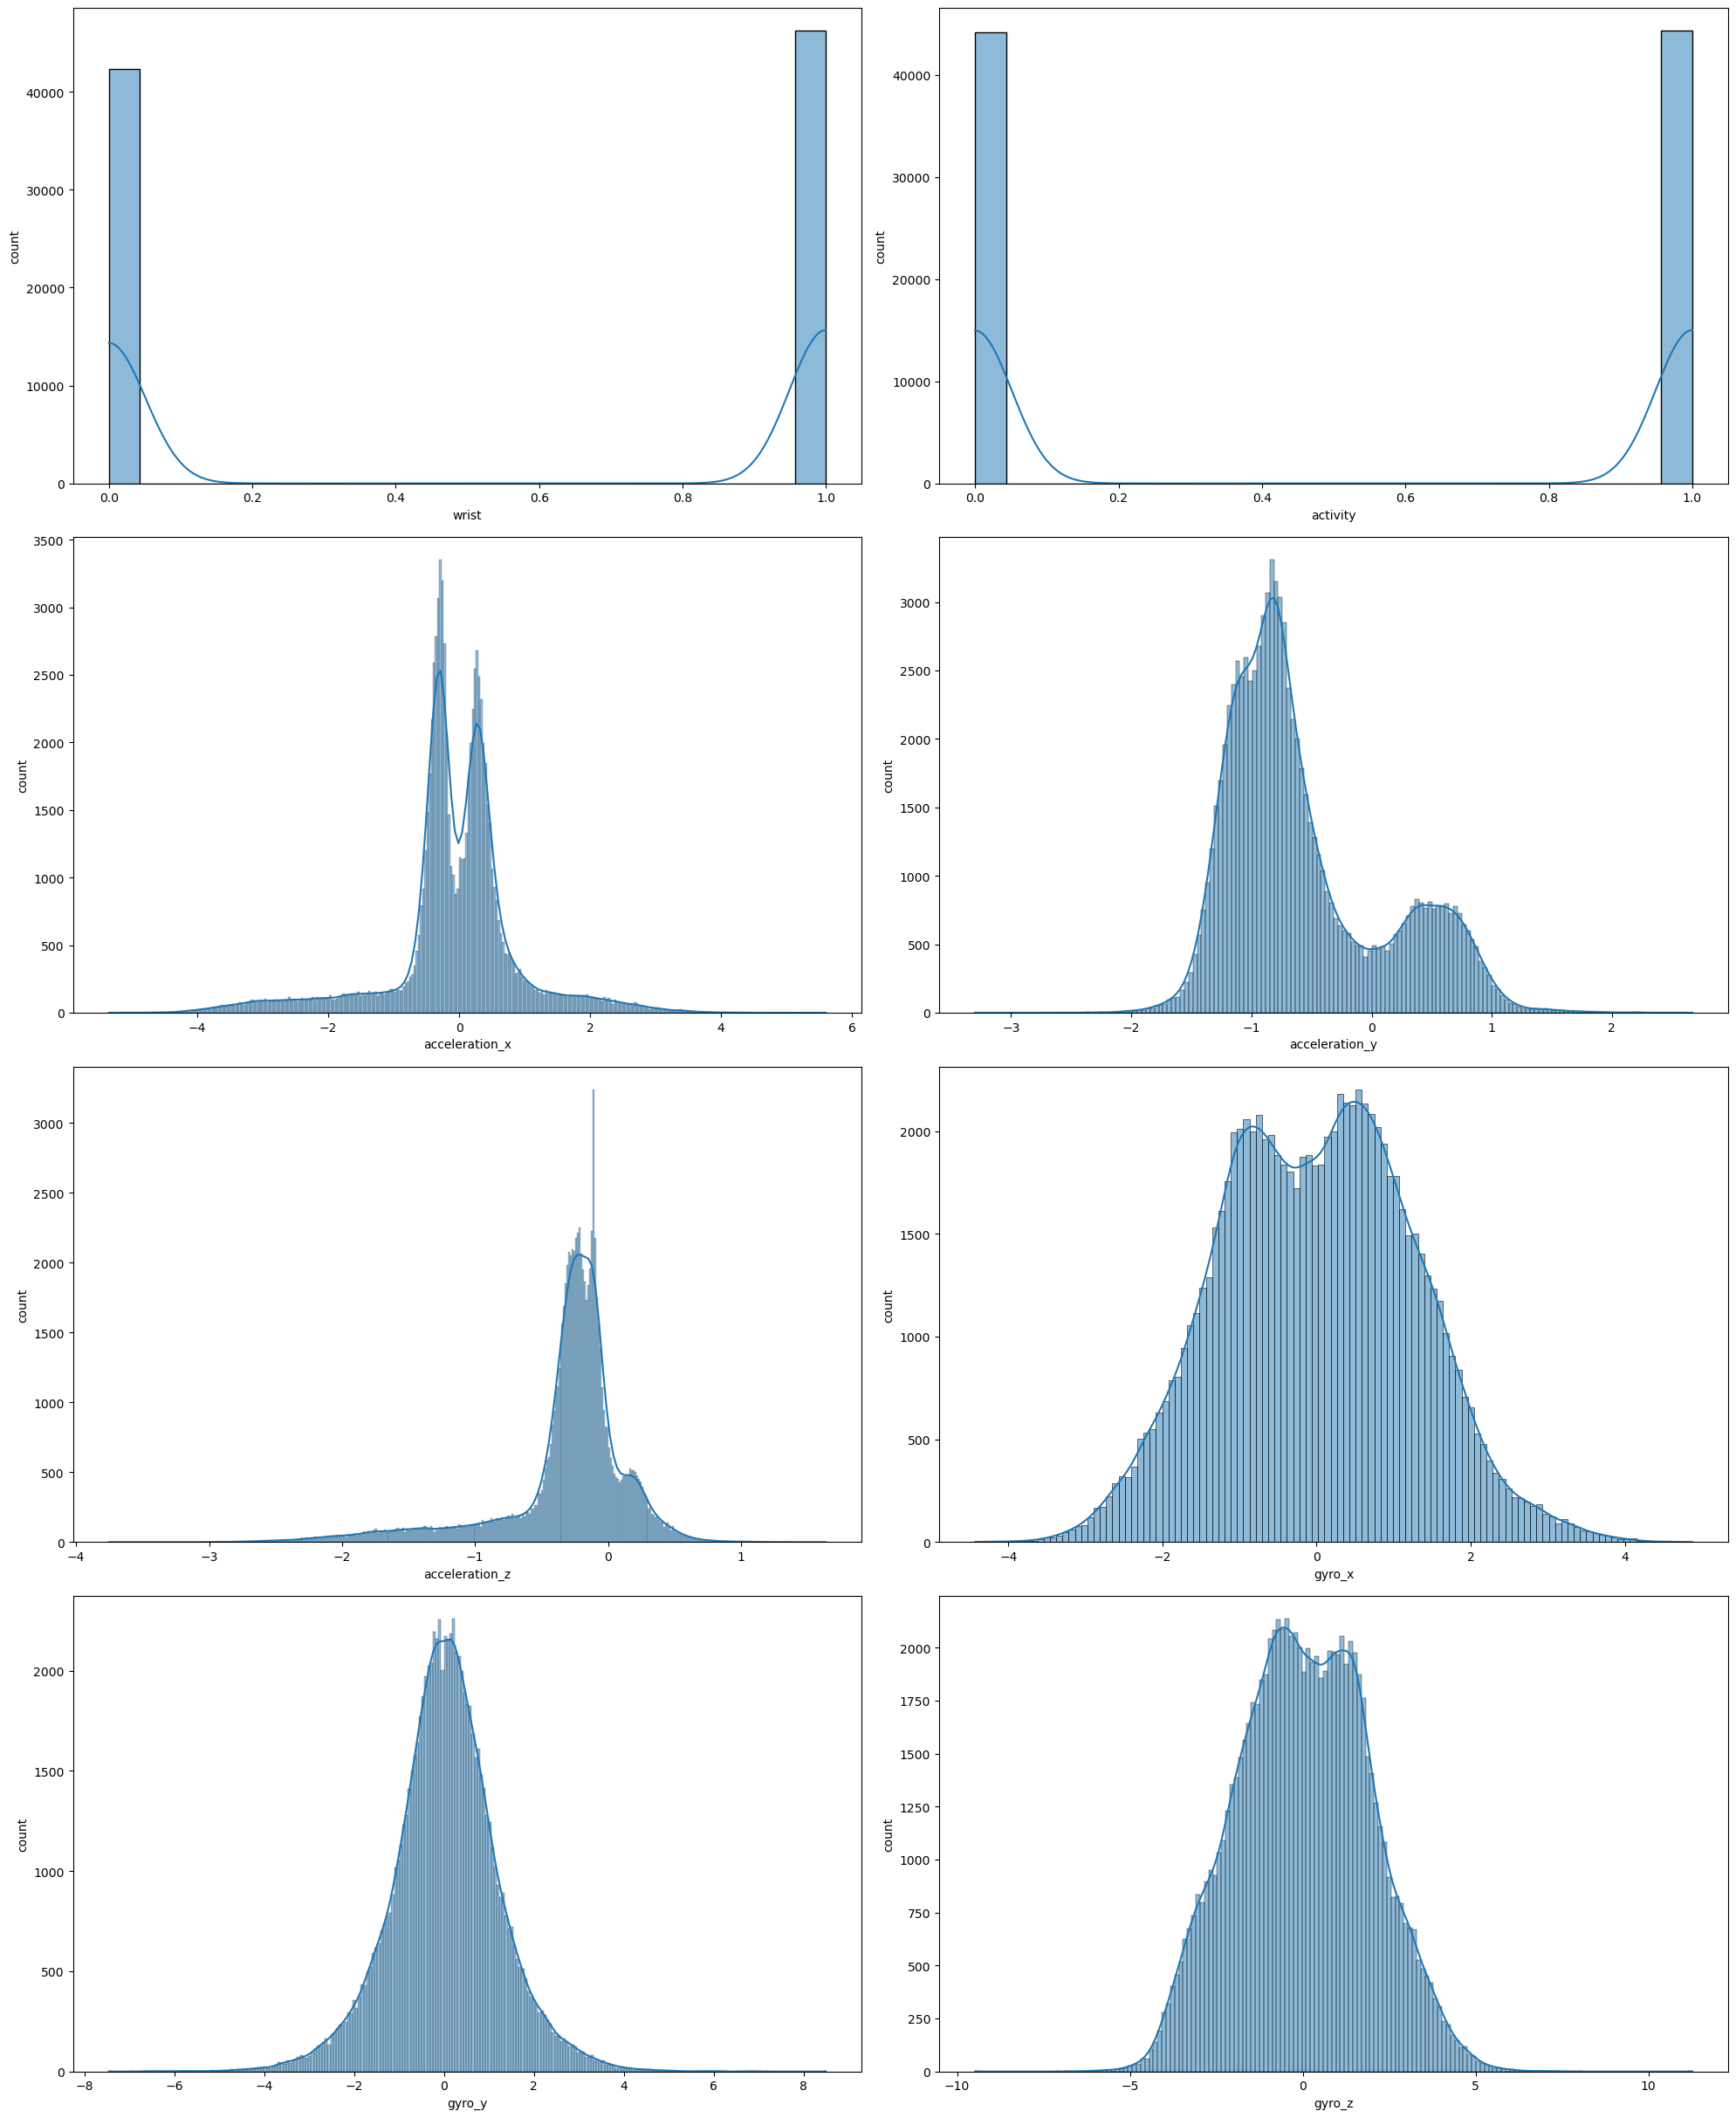

In [7]:
plt.figure(figsize=(20,30), facecolor='white')  # Sets the overall figure size and background color for all subplots

plot = 1  # Counter to track subplot position

for i in data:  # Looping through each column in the DataFrame 'data'
    if plot <= 10:  # Limits the number of plots to 10 (to prevent overcrowding)
        plt.subplot(5, 2, plot)  # Creates a subplot grid of 5 rows and 2 columns, and selects the current subplot
        sns.histplot(x=data[i], kde=1)  # Plots a histogram with KDE (kernel density estimate) for smoother distribution curve
        plt.xlabel(i, fontsize=10)  # Sets the x-axis label to the column name
        plt.ylabel('count', fontsize=10)  # Sets the y-axis label

    plot += 1  # Move to the next subplot position

plt.tight_layout()  # Adjusts spacing between subplots to prevent overlap

# Bivariant analysis

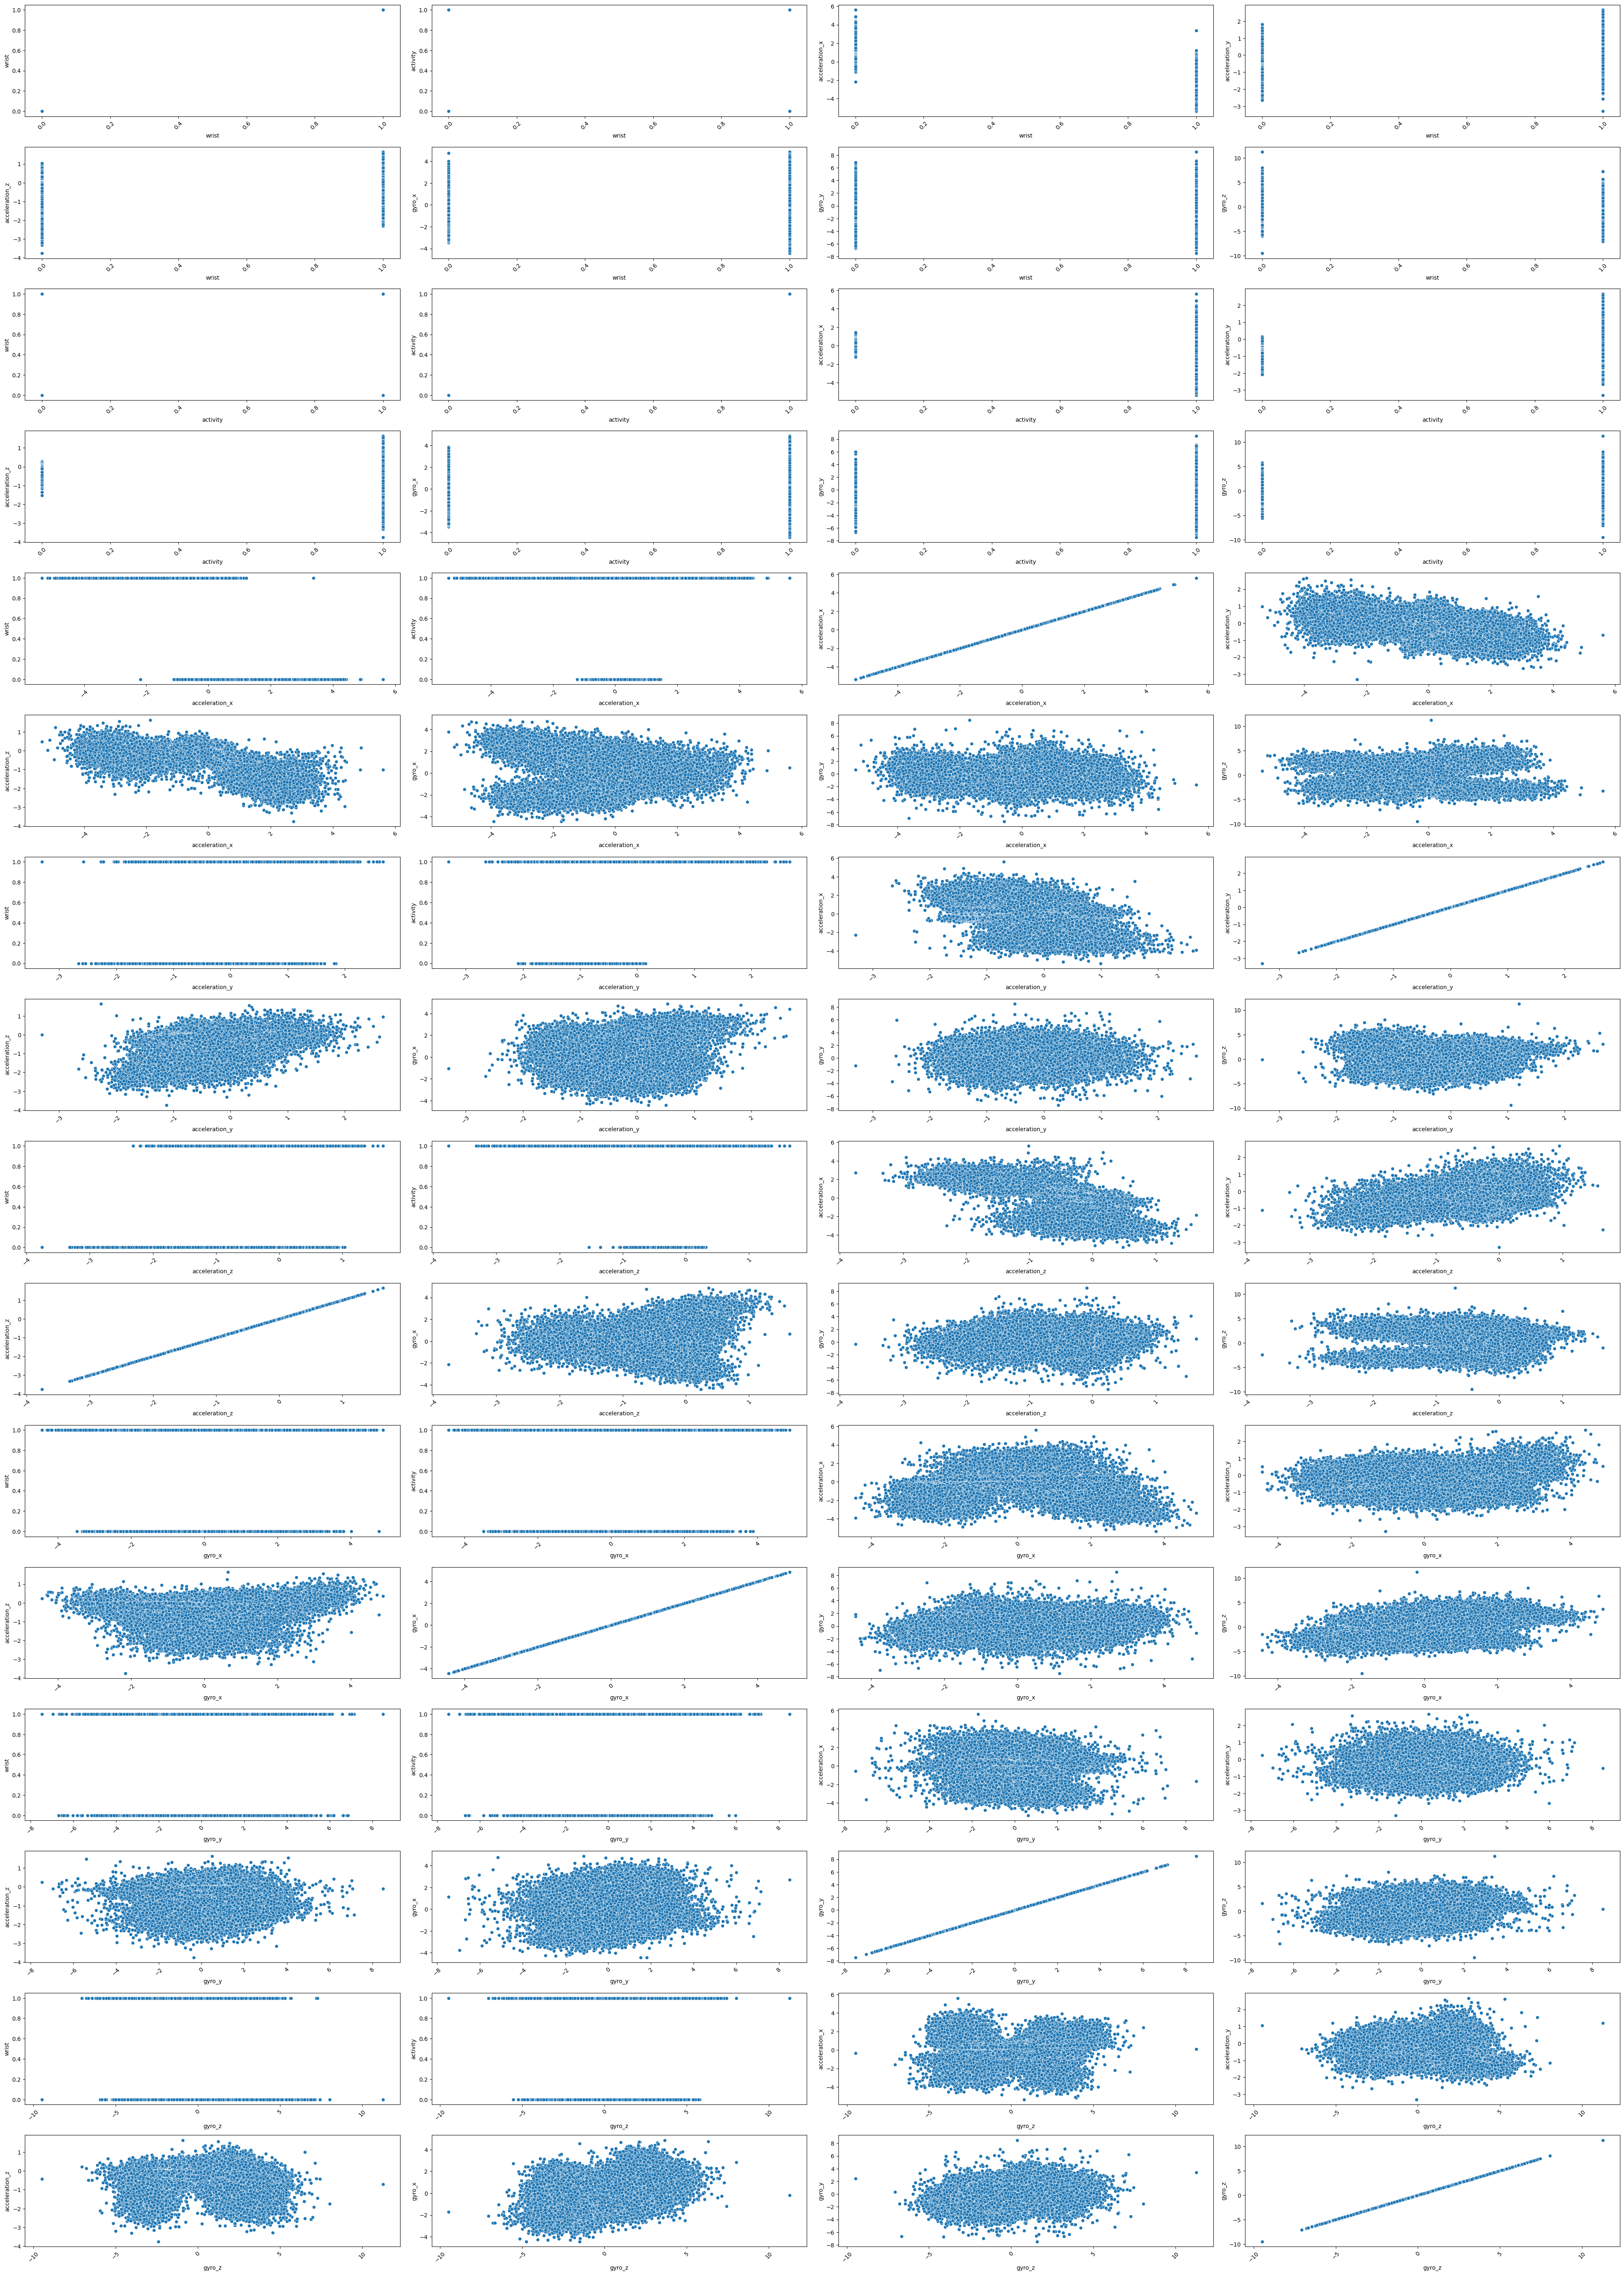

In [8]:
plt.figure(figsize=(40, 56), facecolor='white')  # Sets up a large figure with white background to hold multiple subplots

plot = 1  # Plot counter to keep track of subplot positions

for i in data:  # Outer loop: goes through each column in the dataset as x-axis
    for j in data:  # Inner loop: goes through each column as y-axis
        if plot <= 65:  # Limits the total number of scatter plots to 65 to avoid overcrowding
            plt.subplot(16, 4, plot)  # Creates a subplot grid (16 rows x 4 columns), selects the current subplot slot
            sns.scatterplot(x=data[i], y=data[j])  # Plots a scatter plot between column `i` (x-axis) and column `j` (y-axis)
            plt.xlabel(i, fontsize=10)  # Sets x-axis label as the column name
            plt.ylabel(j, fontsize=10)  # Sets y-axis label as the column name
            plt.xticks(rotation=45)  # Rotates x-axis ticks to avoid overlapping text
            plot += 1  # Increments subplot position
plt.tight_layout()  # Adjusts spacing to prevent overlapping of subplots

## multivarient analysis

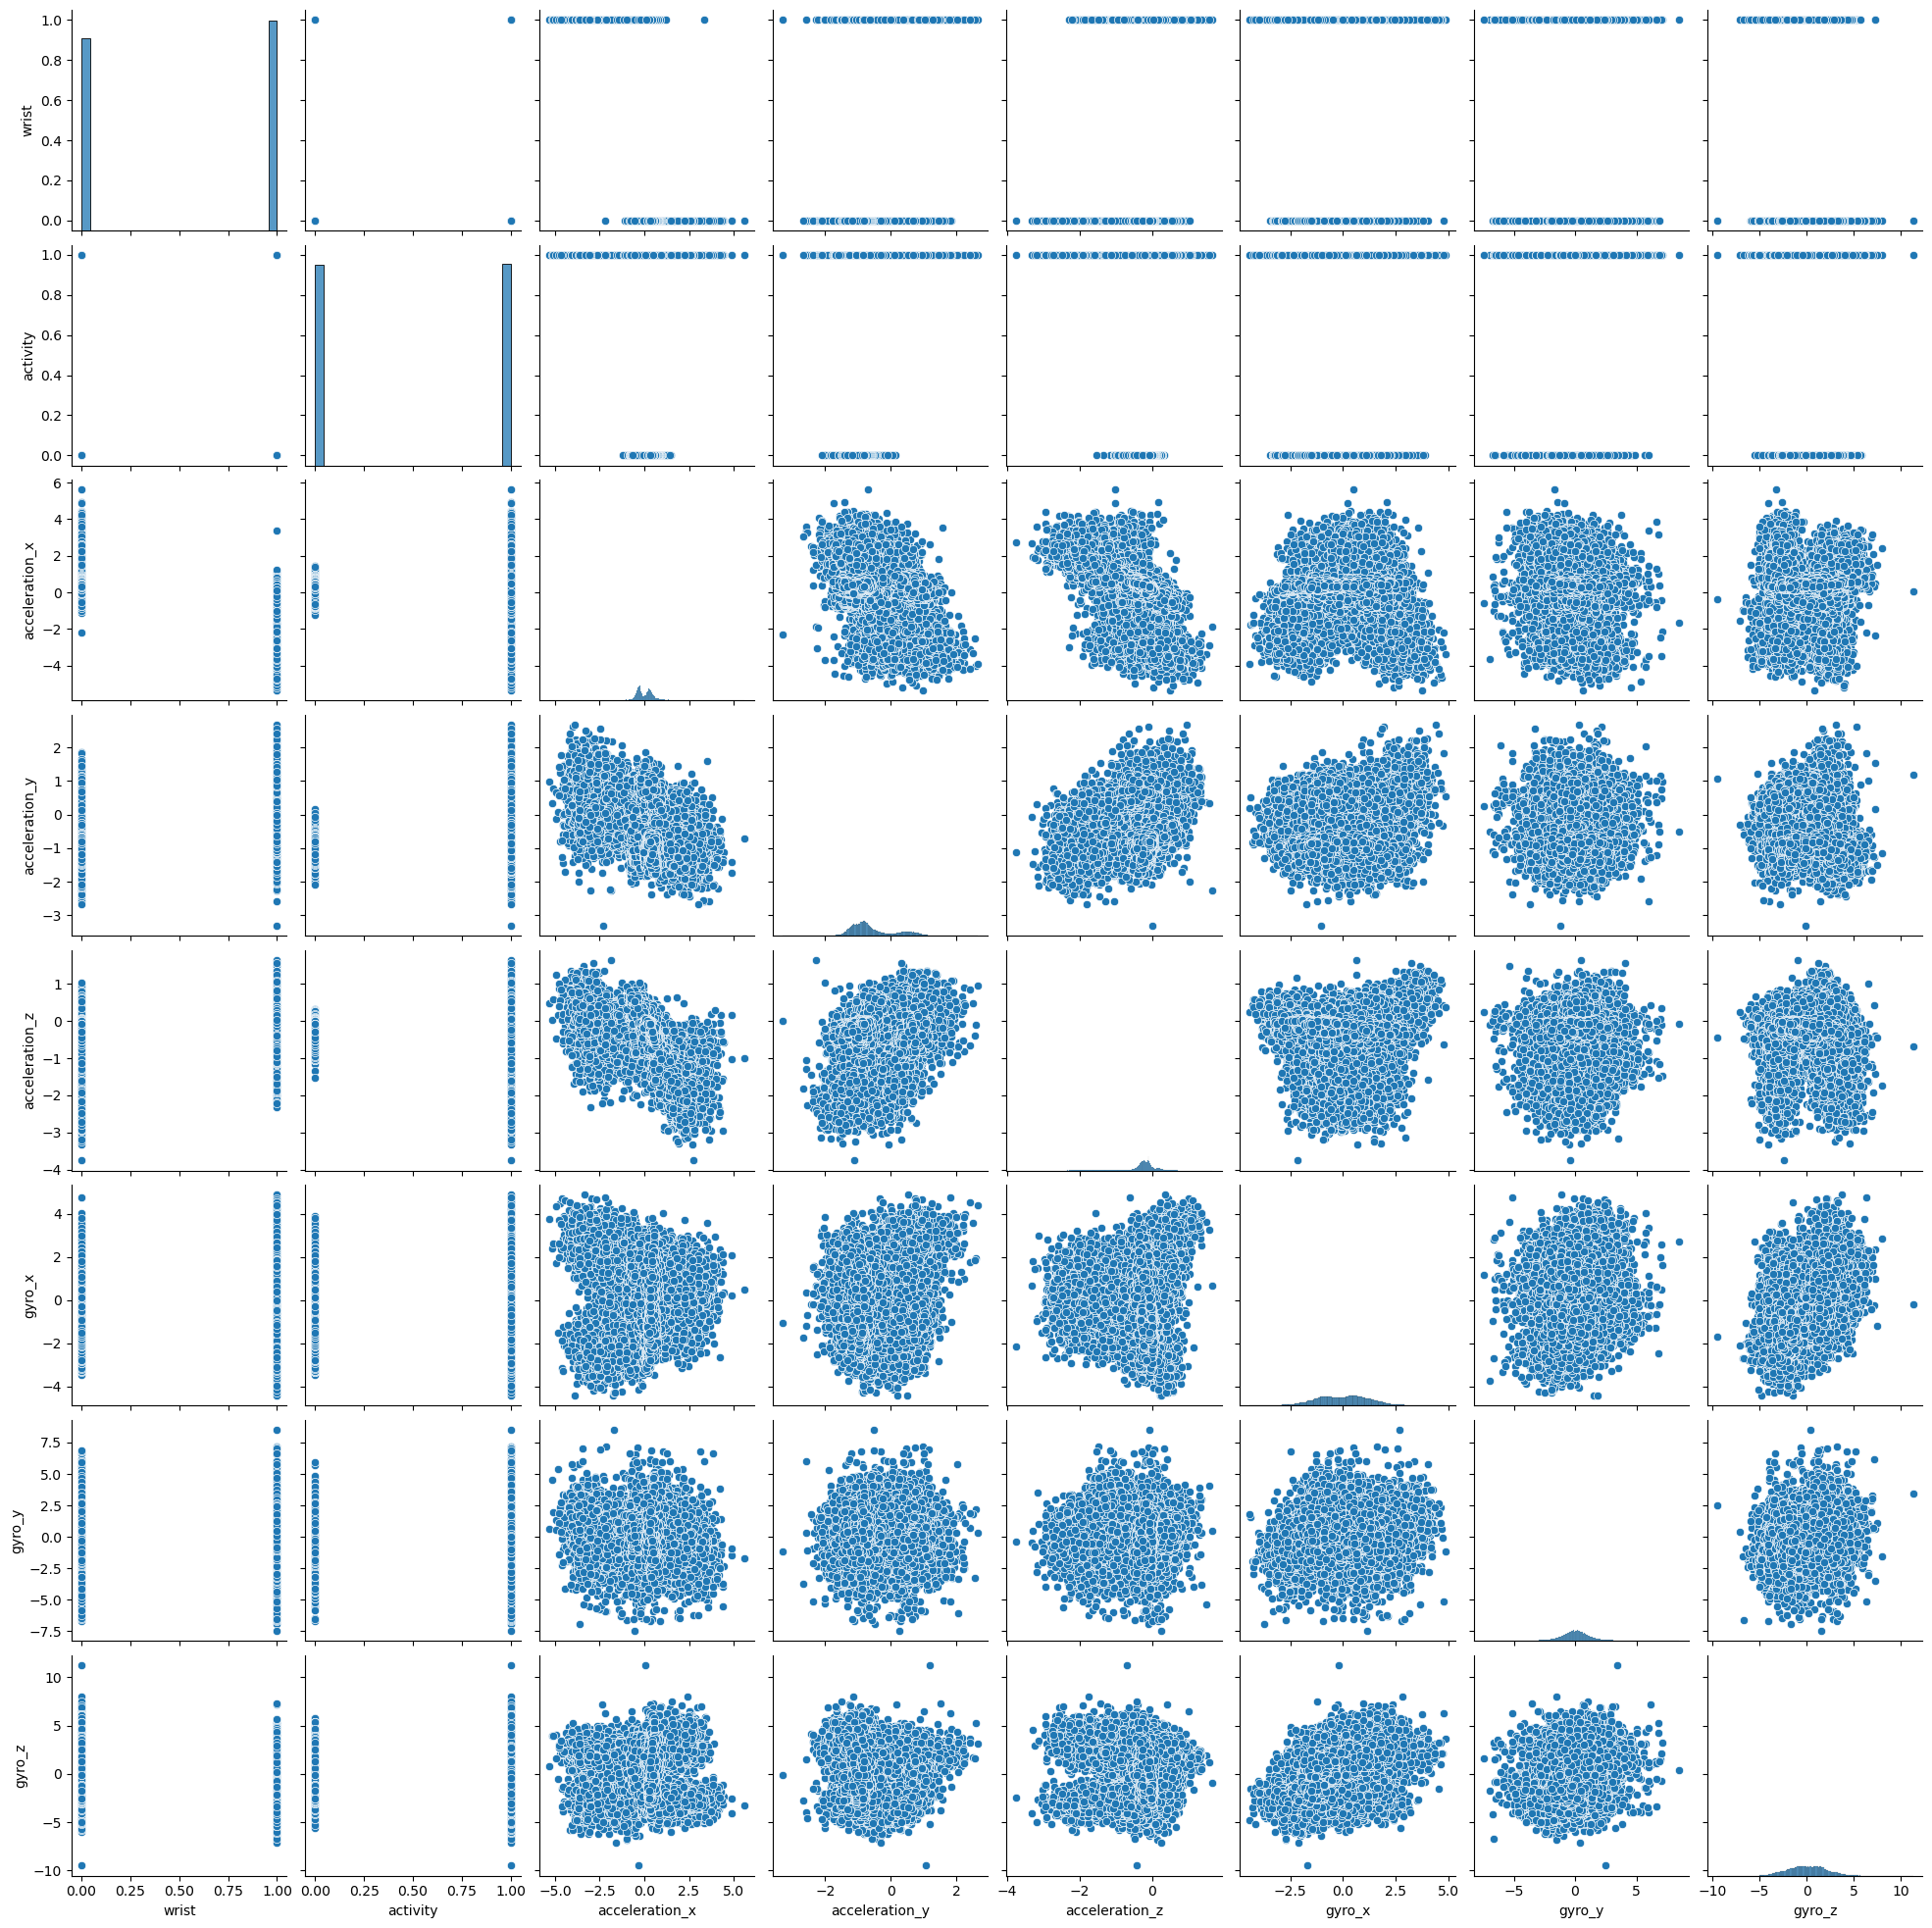

In [9]:
sns.pairplot(data)  # Creates a grid of scatter plots and histograms for each pair of numeric variables in the DataFrame

### Checking correlation between features using heatmap 

<Axes: >

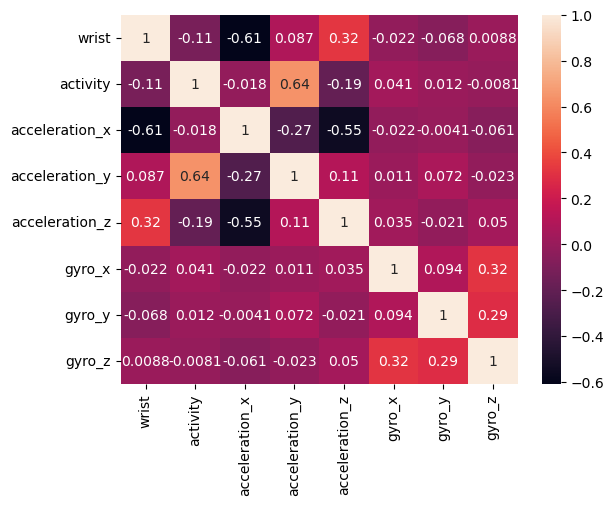

In [13]:
sns.heatmap(data.corr(),annot=True)  # Creates a heatmap of the correlation matrix with numeric values shown inside each cell

## Checking of null values

In [14]:
data.isnull().sum() # checking for null values in columns

wrist             0
activity          0
acceleration_x    0
acceleration_y    0
acceleration_z    0
gyro_x            0
gyro_y            0
gyro_z            0
dtype: int64

## checking for outliers 

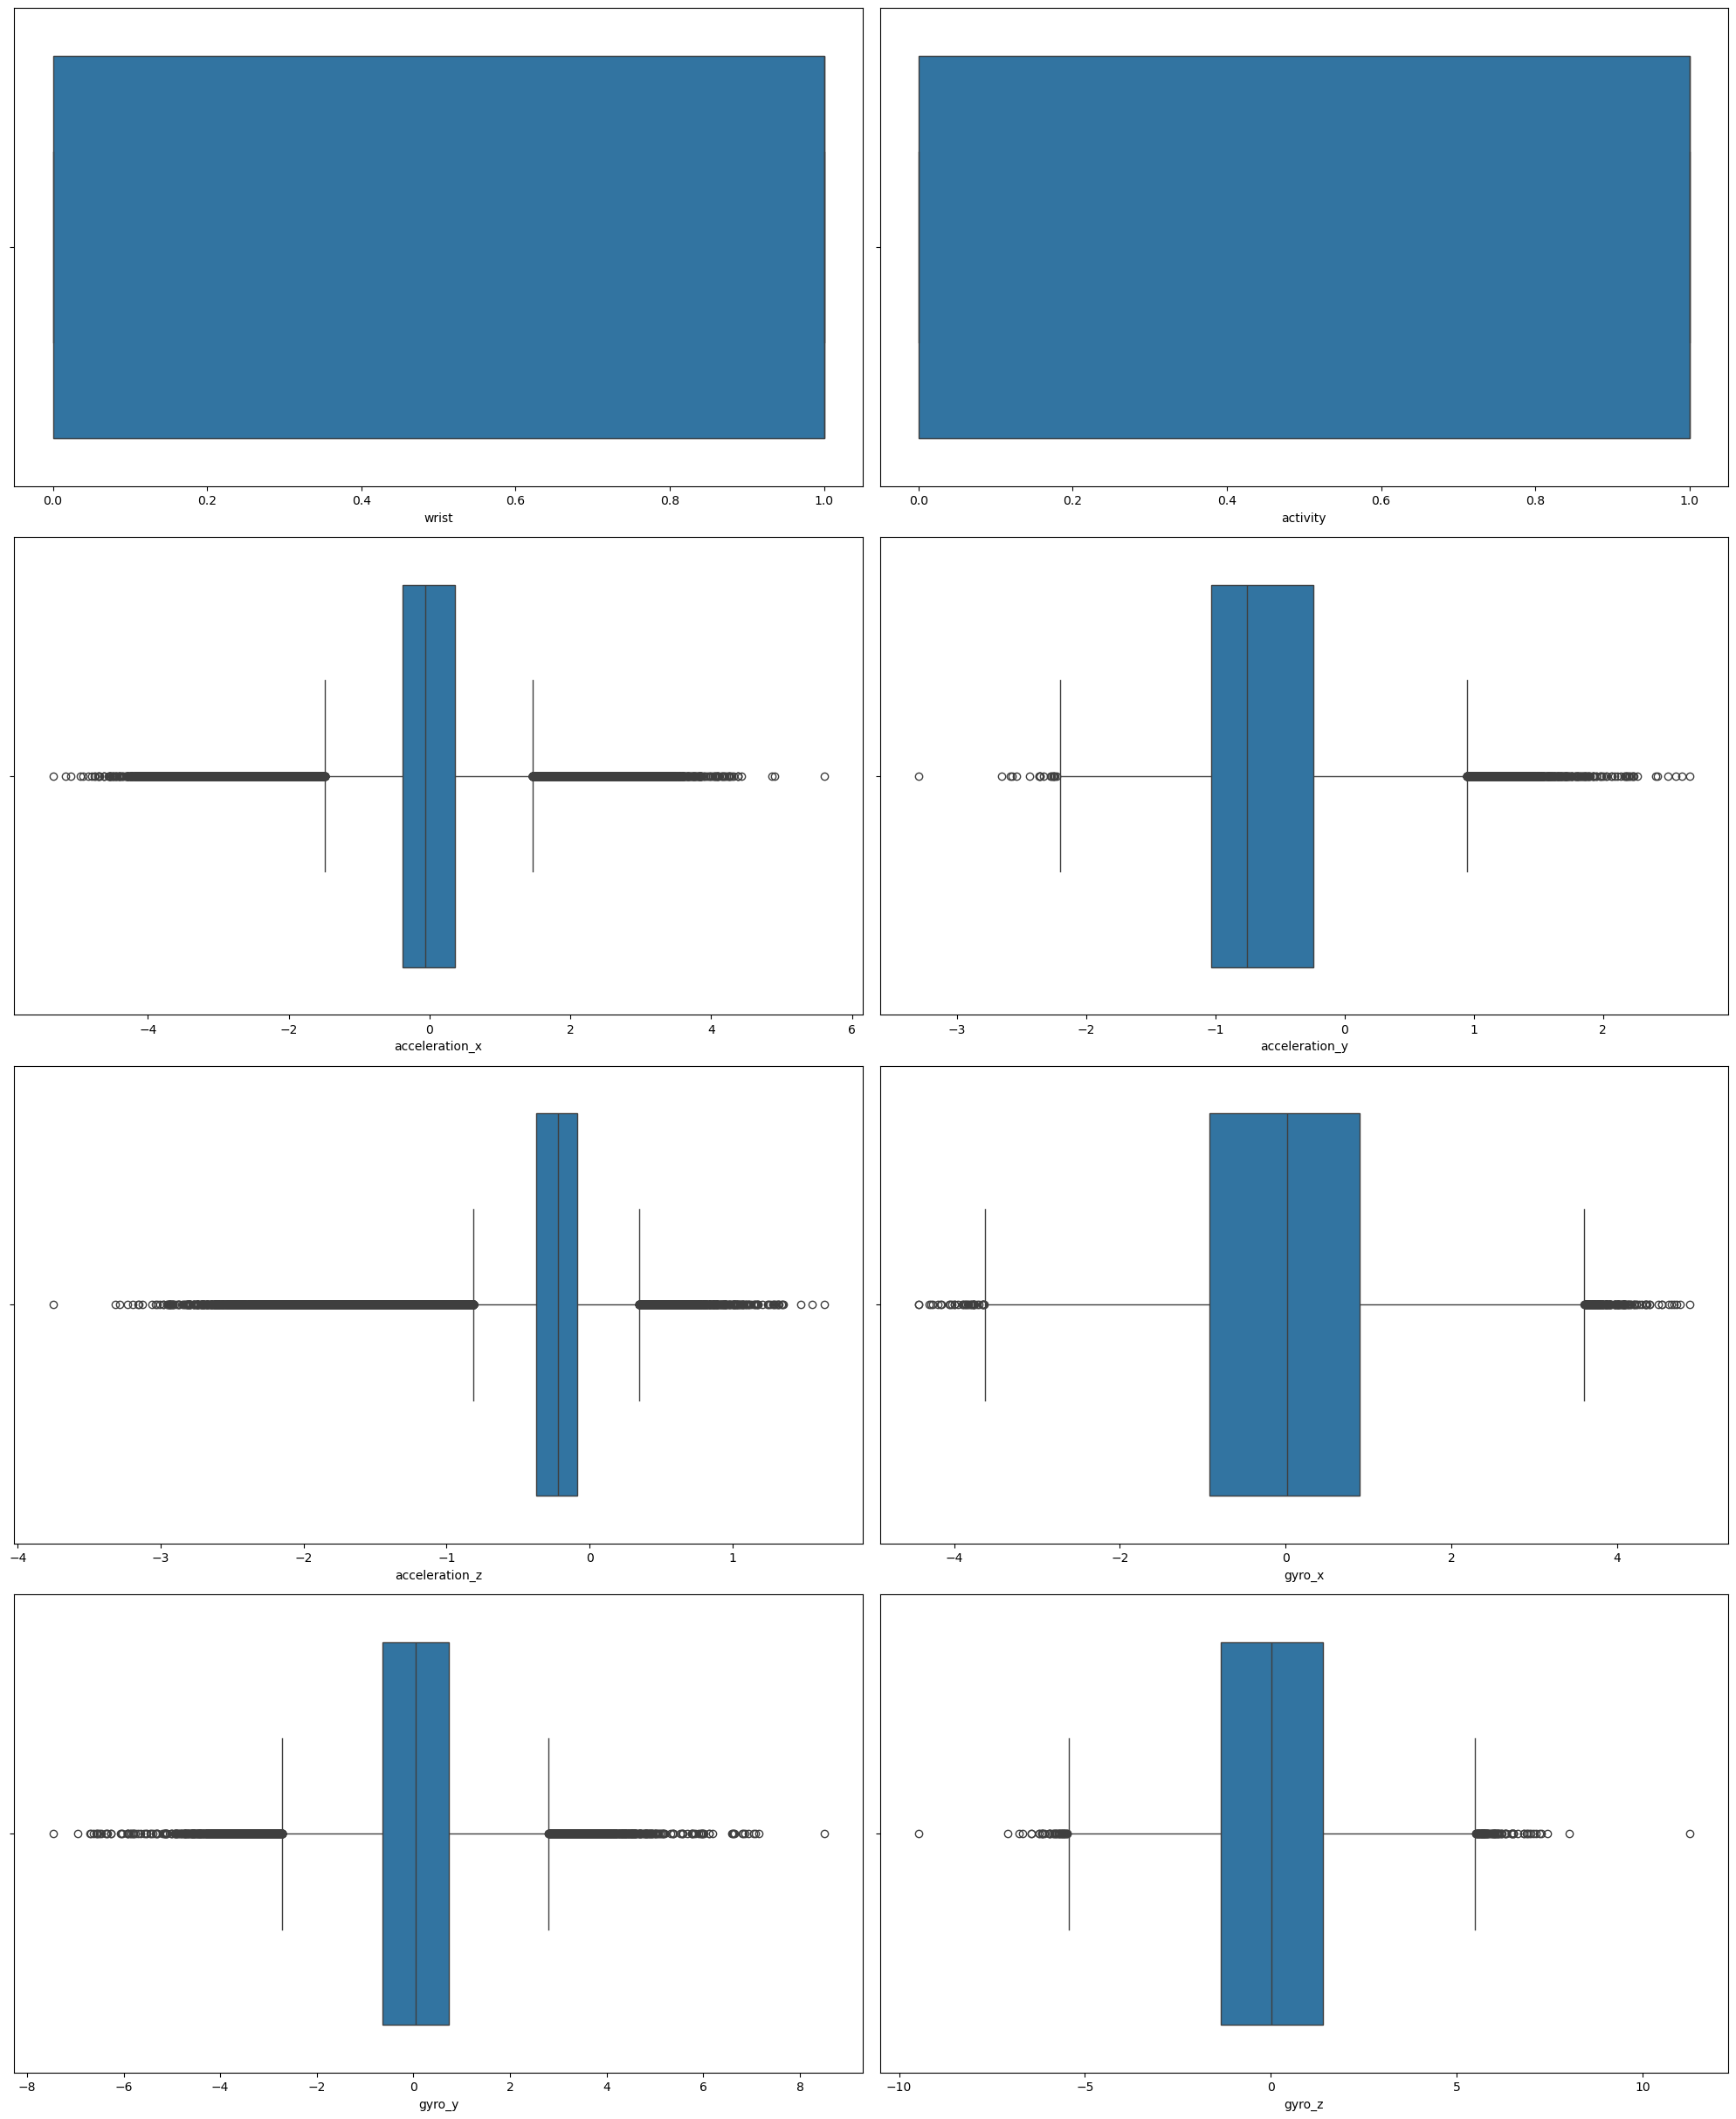

In [15]:
# finding outliers using the boxplot 
plt.figure(figsize=(20,30))
plot = 1
for i in data:
    if plot<=10:
        plt.subplot(5,2,plot)
        sns.boxplot(x=data[i])
        plt.xlabel(i,fontsize=10)
    plot+=1
plt.tight_layout()
        

## Here almost in every column there is outliers 

## Removing outliers using IQR method

In [16]:
for i in data:  # Loop through each column in the DataFrame
    q1 = data[i].quantile(0.25)  # Calculate the 1st quartile (25th percentile) for column i
    q3 = data[i].quantile(0.75)  # Calculate the 3rd quartile (75th percentile) for column i
    iqr = q3 - q1  # Compute the Interquartile Range (IQR)

    lower = q1 - 1.5 * iqr  # Define the lower bound for detecting outliers
    upper = q3 + 1.5 * iqr  # Define the upper bound for detecting outliers

    # Identify values outside the IQR range and replace them with the median of the column
    data.loc[(data[i] < lower) | (data[i] > upper), i] = data[i].median()

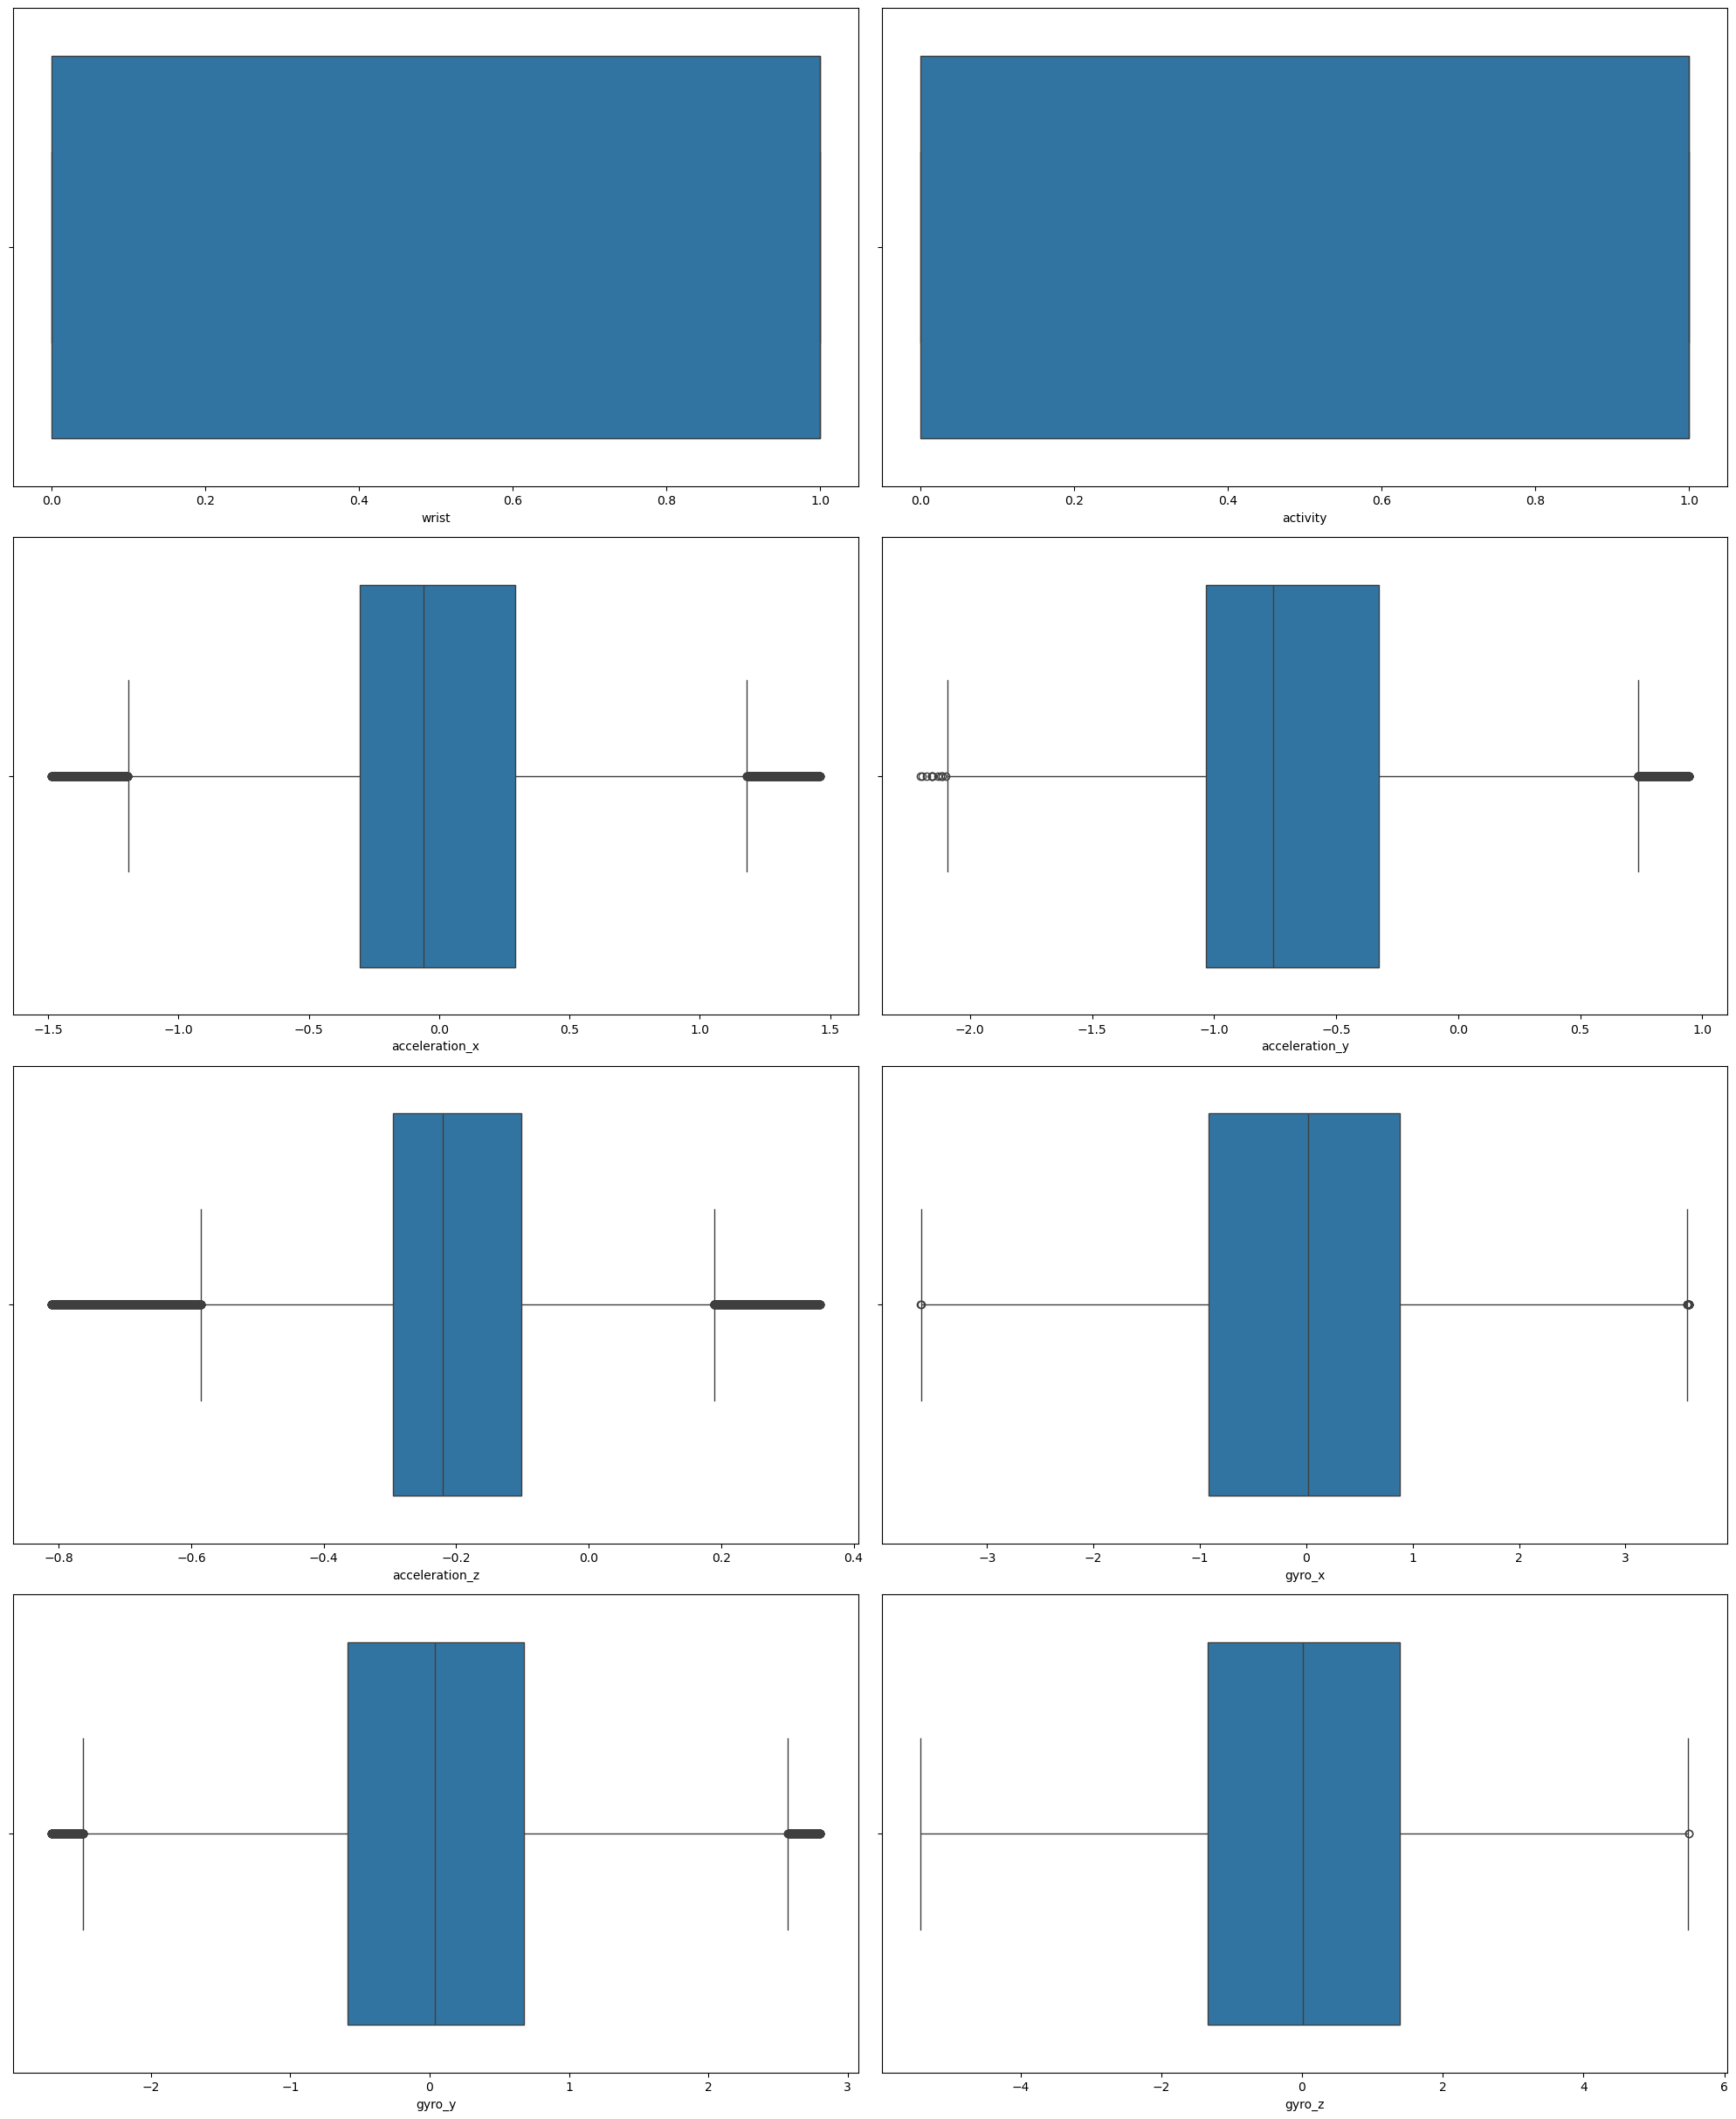

In [17]:
# again checking that outliers are removed or not 
plt.figure(figsize=(20,30))
plot = 1
for i in data:
    if plot<=10:
        plt.subplot(5,2,plot)
        sns.boxplot(x=data[i])
        plt.xlabel(i,fontsize=10)
    plot+=1
plt.tight_layout()

## Here our data is already in ready to use ,
## No need for Standard Scaling and encoding

## Dividing the data in to x and y 

In [18]:
data.head()

,wrist,activity,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,0,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,0,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,0,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,0,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922


In [19]:
x = data.drop('activity', axis=1)  # Drops the 'activity' column from the dataset and stores the remaining features in variable 'x' (independent variables)
y = data.activity  # Stores the 'activity' column (target/dependent variable) in variable 'y'

In [20]:
x

,wrist,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
0,0,0.2650,-0.7814,-0.0076,-0.0590,0.0325,-2.9296
1,0,0.6722,-1.1233,-0.2344,-0.1757,0.0208,0.1269
2,0,0.4399,-1.4817,0.0722,-0.9105,0.1063,-2.4367
3,0,0.3031,-0.8125,0.0888,0.1199,-0.4099,-2.9336
4,0,0.4814,-0.9312,0.0359,0.0527,0.4379,2.4922
...,...,...,...,...,...,...,...
88583,0,0.3084,-0.8376,-0.1327,0.4823,2.0124,0.6048
88584,0,0.4977,-1.0027,-0.4397,0.1022,-1.2565,-0.0761
88585,0,0.4587,-1.1780,-0.2827,-1.4500,-0.2792,-1.2616
88586,0,0.2590,-0.8582,-0.0759,-1.5165,0.4560,-1.7755


In [21]:
y

0        0
1        0
2        0
3        0
4        0
        ..
88583    0
88584    0
88585    0
88586    0
88587    0
Name: activity, Length: 88588, dtype: int64

## splitting the data into train ans test split

In [22]:
from sklearn.model_selection import train_test_split  # Imports the function to split data into training and testing sets

# Splits the features and labels into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=45)

In [23]:
x_train

,wrist,acceleration_x,acceleration_y,acceleration_z,gyro_x,gyro_y,gyro_z
27050,1,-0.2076,-0.5271,-0.1109,-1.1696,-1.2694,1.5077
2712,0,0.1908,0.5302,-0.2348,-0.6436,0.6046,0.7143
59189,0,-0.1874,-0.2901,0.0788,0.8075,-0.2472,1.4391
84374,0,0.4851,0.3693,-0.5040,-0.6786,0.1028,-2.8859
64263,0,-0.0694,-0.4372,-0.1035,1.4377,-0.4080,-0.4263
...,...,...,...,...,...,...,...
12895,1,-0.0595,-0.3998,-0.0716,2.1446,-0.3511,1.5752
60960,0,0.6186,0.4057,-0.6877,-0.6516,1.2686,1.9665
6012,1,-0.2450,-1.2228,-0.2834,2.0829,1.4722,-1.7638
63107,0,-0.0595,-0.6655,-0.2210,0.4341,0.5519,2.3836


In [24]:
y_train

27050    0
2712     1
59189    1
84374    1
64263    1
        ..
12895    1
60960    1
6012     0
63107    1
6558     0
Name: activity, Length: 70870, dtype: int64

## Applying different machine learnings models 

In [25]:
# Since it is a classification problem, we use classification metrics for model evaluation
from sklearn.metrics import f1_score, accuracy_score, classification_report

## 1.Logistic Regression

In [26]:
from sklearn.linear_model import LogisticRegression  # Imports the Logistic Regression model from scikit-learn

lr = LogisticRegression()  # Creates an instance of the Logistic Regression model with default parameters

lr.fit(x_train, y_train)  # Trains (fits) the model using the training data (features and labels)

LogisticRegression()

In [27]:
y_train_pred = lr.predict(x_train)
y_pred  = lr.predict(x_test)

In [28]:
print(f'Training Accuracy: {accuracy_score(y_train,y_train_pred)}')
print(f'Testing Accuracy: {accuracy_score(y_test,y_pred)}')

Training Accuracy: 0.8341752504585861
Testing Accuracy: 0.829664747714189


In [29]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.81      0.87      0.84      8911
           1       0.86      0.79      0.82      8807

    accuracy                           0.83     17718
   macro avg       0.83      0.83      0.83     17718
weighted avg       0.83      0.83      0.83     17718



## 2.SVM

In [30]:
from sklearn.svm import SVC  # Imports the Support Vector Classification (SVC) model from scikit-learn

svm = SVC()  # Creates an instance of the SVM classifier with default parameters (RBF kernel)

svm.fit(x_train, y_train)  # Trains (fits) the SVM model using the training data

SVC()

In [35]:
y_train_pred = svm.predict(x_train)
y_pred = svm.predict(x_test)


In [36]:
print(f'Training Accuracy: {accuracy_score(y_train,y_train_pred)}')
print(f'Testing Accuracy: {accuracy_score(y_test,y_pred)}')

Training Accuracy: 0.9778749823620714
Testing Accuracy: 0.979060842081499


In [37]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.97      0.99      0.98      8911
           1       0.99      0.97      0.98      8807

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718



## 3.decision Tree

In [38]:
from sklearn.tree import DecisionTreeClassifier  # Imports the Decision Tree Classifier from scikit-learn

dt = DecisionTreeClassifier()  # Creates a Decision Tree model instance with default parameters

dt.fit(x_train, y_train)  # Trains (fits) the Decision Tree using the training features and labels

DecisionTreeClassifier()

In [39]:
y_train_pred = dt.predict(x_train)
y_pred = dt.predict(x_test)

In [40]:
print(f'Training Accuracy: {accuracy_score(y_train,y_train_pred)}')
print(f'Testing Accuracy: {accuracy_score(y_test,y_pred)}')

Training Accuracy: 1.0
Testing Accuracy: 0.9839146630545208


In [41]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.98      0.98      8911
           1       0.98      0.98      0.98      8807

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718



## 4.Random Forest

In [42]:
from sklearn.ensemble import RandomForestClassifier  # Imports the Random Forest Classifier from scikit-learn

rf = RandomForestClassifier()  # Creates a Random Forest model with default parameters (100 trees)

rf.fit(x_train, y_train)  # Trains (fits) the Random Forest using the training data

RandomForestClassifier()

In [43]:
y_train_pred = rf.predict(x_train)
y_pred = rf.predict(x_test)

In [44]:
print(f'Training Accuracy: {accuracy_score(y_train,y_train_pred)}')
print(f'Testing Accuracy: {accuracy_score(y_test,y_pred)}')

Training Accuracy: 1.0
Testing Accuracy: 0.9930014674342477


In [45]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.99      0.99      0.99      8911
           1       0.99      0.99      0.99      8807

    accuracy                           0.99     17718
   macro avg       0.99      0.99      0.99     17718
weighted avg       0.99      0.99      0.99     17718



## 5.Gradient Boosting

In [46]:
from sklearn.ensemble import GradientBoostingClassifier  # Imports the Gradient Boosting Classifier from scikit-learn

gb = GradientBoostingClassifier()  # Creates a Gradient Boosting model with default parameters

gb.fit(x_train, y_train)  # Trains (fits) the model using the training data

GradientBoostingClassifier()

In [47]:
y_train_pred = gb.predict(x_train)
y_pred = gb.predict(x_test)

In [48]:
print(f'Training Accuracy: {accuracy_score(y_train,y_train_pred)}')
print(f'Testing Accuracy: {accuracy_score(y_test,y_pred)}')

Training Accuracy: 0.9819669817976577
Testing Accuracy: 0.9839146630545208


In [49]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.98      0.99      0.98      8911
           1       0.99      0.98      0.98      8807

    accuracy                           0.98     17718
   macro avg       0.98      0.98      0.98     17718
weighted avg       0.98      0.98      0.98     17718



## Xtreme Gradient Boosting

In [52]:
!pip install xgboost

In [53]:
from xgboost import XGBClassifier  # Imports the XGBoost classifier — an optimized gradient boosting algorithm

xgb = XGBClassifier()  # Creates an instance of XGBoost with default hyperparameters

xgb.fit(x_train, y_train)  # Trains the XGBoost model using the training data

XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, ...)

In [54]:
y_xgb_train = xgb.predict(x_train)
y_xgb_pred = xgb.predict(x_test)

In [55]:
print('Training Accuracy:',f1_score(y_train,y_xgb_train))
print('Testing Accuracy:',f1_score(y_test,y_xgb_pred))

Training Accuracy: 0.9985226041564069
Testing Accuracy: 0.9930689694352914


## Why We Didn’t Do Hyperparameter Tuning

We didn’t use hyperparameter tuning because all the models gave good results with their default settings. The dataset was clean and balanced, so the models worked well without extra adjustments. Also, there was no overfitting, so we didn’t feel the need to tune anything. To keep things simple and quick, we focused on comparing models first. Tuning can be done later if needed to improve performance.

# Best Model

In this project, we worked on a classification problem to detect whether a person is walking or running using motion sensor data from a wearable device. 

We trained and tested the following machine learning models:
1. **Logistic Regression**
2. **Support Vector Machine (SVM)**
3. **Decision Tree**
4. **Random Forest**
5. **Gradient Boosting**
6. **XGBoost**

---

#  Best Performing Model: **XGBoost**

Out of all the models, **XGBoost Classifier** gave the best results. It showed high accuracy and F1-score on both training and testing sets.

---

###  Why XGBoost Was Best:

- It captures both simple and complex patterns in the data.
- It uses boosting, which means it builds a strong model by combining multiple weak ones.
- It handles noisy sensor data and outliers better than many other models.
- It generalizes well — not just high training performance, but also performs well on new (unseen) test data.

---

#  Generalization

Other models like Random Forest and Gradient Boosting also gave decent results, but:
- **Decision Tree** slightly overfit the training data.
- **SVM** and **Logistic Regression** couldn’t capture complex motion patterns as well.
- **XGBoost** balanced performance and generalization the best.

---



#  Final Conclusion

In this project, we started with raw motion sensor data collected from wearable devices and built a machine learning model that can detect whether a person is **walking** or **running**.

We did the following:
- Cleaned the data by removing unnecessary columns like `date`, `time`, and `username`.
- Explored and visualized the data using histograms, scatter plots, pair plots, and heatmaps to understand relationships.
- Removed outliers using the IQR (Interquartile Range) method to make the data more reliable.
- Split the data into training and testing sets.
- Applied classification models (like Random Forest, SVM, or others – depending on your model choice).
- Evaluated the model using metrics like accuracy and F1-score.

 **Problem Solved:**  
We successfully trained a model that can predict with good accuracy whether a person is walking or running based on accelerometer and gyroscope data.

---

#  Where Can This Be Used?

This kind of activity recognition has many real-world applications:
- **Fitness apps** can use it to log exercises like walking or running.
- **Healthcare monitoring** systems can track patient activity or detect mobility issues.
- **Smartwatches and wearables** can use it to power features like auto-exercise detection.
- **Elder care** systems can alert caregivers if there's unusual activity or lack of movement.
- **Insurance companies** can validate physical activity for rewards or discounts.

This project shows how motion sensor data and machine learning can be combined to solve practical problems and improve user experiences in health and wellness tech.

In [ ]:
# Additional code: save the trained XGBoost model for the Streamlit web app
import joblib

# Keep the same feature columns and their order used during model training
feature_names = list(x_train.columns)

# Save the already-trained XGBoost model (xgb) and feature order
joblib.dump(
    {
        "model": xgb,
        "feature_names": feature_names
    },
    "model.pkl"
)

print("Model saved successfully as model.pkl")
